In [47]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
import numpy as np
import matplotlib.pyplot as plt
import os

In [48]:
print(f"TensorFlow Version: {tf.__version__}")
print(f"GPU Available: {tf.config.list_physical_devices('GPU')}")

TensorFlow Version: 2.20.0
GPU Available: []


In [49]:
PROJECT_DIR = r"D:\CSE Code\CSE465 Project"
TRAIN_DIR = os.path.join(PROJECT_DIR, "dataset", "train")
VAL_DIR = os.path.join(PROJECT_DIR, "dataset", "validation")
MODEL_SAVE_PATH = os.path.join(PROJECT_DIR, "model", "banknote_classifier.h5")

IMG_SIZE = 224
BATCH_SIZE = 32
EPOCHS = 50

print(f"Image Size: {IMG_SIZE}x{IMG_SIZE}")
print(f"Batch Size: {BATCH_SIZE}")
print(f"Epochs: {EPOCHS}")


Image Size: 224x224
Batch Size: 32
Epochs: 50


In [50]:
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.15,
    zoom_range=0.15,
    horizontal_flip=True,
    fill_mode='nearest'
)

val_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=True
)

val_generator = val_datagen.flow_from_directory(
    VAL_DIR,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=False
)

print(f"\nClass Indices: {train_generator.class_indices}")
print(f"Training Samples: {train_generator.samples}")
print(f"Validation Samples: {val_generator.samples}")


Found 6794 images belonging to 2 classes.
Found 1360 images belonging to 2 classes.

Class Indices: {'fake': 0, 'real': 1}
Training Samples: 6794
Validation Samples: 1360


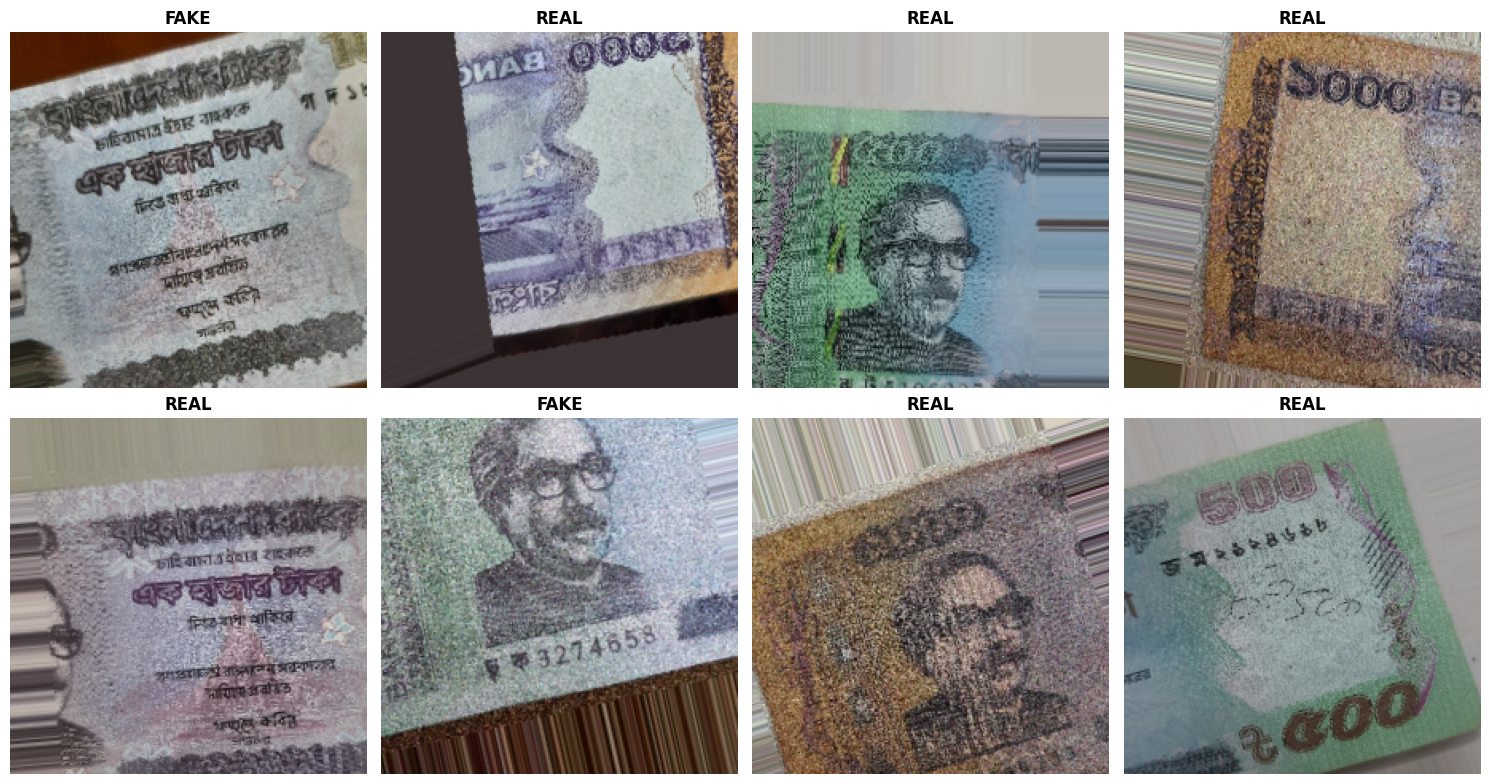

In [51]:
sample_images, sample_labels = next(train_generator)

fig, axes = plt.subplots(2, 4, figsize=(15, 8))
for idx in range(8):
    row = idx // 4
    col = idx % 4
    axes[row, col].imshow(sample_images[idx])
    label = "REAL" if sample_labels[idx] == 1 else "FAKE"
    axes[row, col].set_title(label, fontweight='bold')
    axes[row, col].axis('off')

plt.tight_layout()
plt.savefig(os.path.join(PROJECT_DIR, "augmented_samples.png"), dpi=150)
plt.show()

In [53]:
base_model = MobileNetV2(
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    include_top=False,
    weights='imagenet'
)

# Freeze base model
base_model.trainable = False

model = keras.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.BatchNormalization(),
    layers.Dropout(0.5),
    layers.Dense(128, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.3),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(1, activation='sigmoid')
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy', keras.metrics.Precision(), keras.metrics.Recall()]
)

print("\n" + "="*60)
print("MODEL ARCHITECTURE")
print("="*60)
model.summary()


MODEL ARCHITECTURE


Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224 (Functional)    │ (None, 7, 7, 1280)          │       2,257,984 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_6           │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_12               │ (None, 1280)                │           5,120 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_18 (Dropout)                 │ (None, 1280)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_18 (Dense)                     │ (None, 128)                 │         163,968 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_13               │ (None, 128)                 │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_19 (Dropout)                 │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_19 (Dense)                     │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_20 (Dropout)                 │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_20 (Dense)                     │ (None, 1)                   │              65 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,435,905 (9.29 MB)

 Trainable params: 175,105 (684.00 KB)

 Non-trainable params: 2,260,800 (8.62 MB)

In [54]:
callbacks = [
    EarlyStopping(
        monitor='val_loss',
        patience=10,
        restore_best_weights=True,
        verbose=1
    ),
    ModelCheckpoint(
        MODEL_SAVE_PATH,
        monitor='val_accuracy',
        save_best_only=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=5,
        min_lr=1e-7,
        verbose=1
    )
]

print("Callbacks configured successfully!")

Callbacks configured successfully!


In [37]:
print("\n" + "="*60)
print("TRAINING STARTED")
print("="*60 + "\n")

history = model.fit(
    train_generator,
    epochs=EPOCHS,
    validation_data=val_generator,
    callbacks=callbacks,
    verbose=1
)

print("\n" + "="*60)
print("TRAINING COMPLETE!")
print("="*60)



TRAINING STARTED

Epoch 1/50
213/213 ━━━━━━━━━━━━━━━━━━━━ 0s 536ms/step - accuracy: 0.7195 - loss: 0.5832 - precision_3: 0.7361 - recall_3: 0.7981
Epoch 1: val_accuracy improved from None to 0.89412, saving model to D:\CSE Code\CSE465 Project\model\banknote_classifier.h5


213/213 ━━━━━━━━━━━━━━━━━━━━ 136s 615ms/step - accuracy: 0.7745 - loss: 0.4868 - precision_3: 0.7880 - recall_3: 0.8252 - val_accuracy: 0.8941 - val_loss: 0.2842 - val_precision_3: 0.8956 - val_recall_3: 0.9211 - learning_rate: 0.0010
Epoch 2/50
213/213 ━━━━━━━━━━━━━━━━━━━━ 0s 505ms/step - accuracy: 0.8306 - loss: 0.3844 - precision_3: 0.8433 - recall_3: 0.8568
Epoch 2: val_accuracy improved from 0.89412 to 0.90662, saving model to D:\CSE Code\CSE465 Project\model\banknote_classifier.h5


213/213 ━━━━━━━━━━━━━━━━━━━━ 122s 572ms/step - accuracy: 0.8351 - loss: 0.3768 - precision_3: 0.8488 - recall_3: 0.8638 - val_accuracy: 0.9066 - val_loss: 0.2369 - val_precision_3: 0.8836 - val_recall_3: 0.9625 - learning_rate: 0.0010
Epoch 3/50
213/213 ━━━━━━━━━━━━━━━━━━━━ 0s 506ms/step - accuracy: 0.8720 - loss: 0.3179 - precision_3: 0.8797 - recall_3: 0.9019
Epoch 3: val_accuracy improved from 0.90662 to 0.93015, saving model to D:\CSE Code\CSE465 Project\model\banknote_classifier.h5


213/213 ━━━━━━━━━━━━━━━━━━━━ 122s 575ms/step - accuracy: 0.8658 - loss: 0.3214 - precision_3: 0.8745 - recall_3: 0.8917 - val_accuracy: 0.9301 - val_loss: 0.2023 - val_precision_3: 0.9185 - val_recall_3: 0.9625 - learning_rate: 0.0010
Epoch 4/50
213/213 ━━━━━━━━━━━━━━━━━━━━ 0s 503ms/step - accuracy: 0.8770 - loss: 0.2975 - precision_3: 0.8843 - recall_3: 0.9067
Epoch 4: val_accuracy improved from 0.93015 to 0.93529, saving model to D:\CSE Code\CSE465 Project\model\banknote_classifier.h5


213/213 ━━━━━━━━━━━━━━━━━━━━ 122s 572ms/step - accuracy: 0.8722 - loss: 0.3109 - precision_3: 0.8776 - recall_3: 0.9008 - val_accuracy: 0.9353 - val_loss: 0.1790 - val_precision_3: 0.9363 - val_recall_3: 0.9508 - learning_rate: 0.0010
Epoch 5/50
213/213 ━━━━━━━━━━━━━━━━━━━━ 0s 503ms/step - accuracy: 0.8735 - loss: 0.2983 - precision_3: 0.8865 - recall_3: 0.8950
Epoch 5: val_accuracy did not improve from 0.93529
213/213 ━━━━━━━━━━━━━━━━━━━━ 122s 570ms/step - accuracy: 0.8784 - loss: 0.3006 - precision_3: 0.8872 - recall_3: 0.9005 - val_accuracy: 0.9353 - val_loss: 0.1809 - val_precision_3: 0.9465 - val_recall_3: 0.9392 - learning_rate: 0.0010
Epoch 6/50
213/213 ━━━━━━━━━━━━━━━━━━━━ 0s 500ms/step - accuracy: 0.8876 - loss: 0.2914 - precision_3: 0.8997 - recall_3: 0.9023
Epoch 6: val_accuracy improved from 0.93529 to 0.93676, saving model to D:\CSE Code\CSE465 Project\model\banknote_classifier.h5


...

213/213 ━━━━━━━━━━━━━━━━━━━━ 123s 575ms/step - accuracy: 0.9291 - loss: 0.1900 - precision_3: 0.9351 - recall_3: 0.9404 - val_accuracy: 0.9684 - val_loss: 0.1067 - val_precision_3: 0.9704 - val_recall_3: 0.9741 - learning_rate: 5.0000e-04
Epoch 30/50
213/213 ━━━━━━━━━━━━━━━━━━━━ 0s 502ms/step - accuracy: 0.9282 - loss: 0.1821 - precision_3: 0.9349 - recall_3: 0.9393
Epoch 30: val_accuracy did not improve from 0.96838
213/213 ━━━━━━━━━━━━━━━━━━━━ 121s 569ms/step - accuracy: 0.9276 - loss: 0.1907 - precision_3: 0.9336 - recall_3: 0.9394 - val_accuracy: 0.9669 - val_loss: 0.1073 - val_precision_3: 0.9667 - val_recall_3: 0.9754 - learning_rate: 5.0000e-04
Epoch 31/50
213/213 ━━━━━━━━━━━━━━━━━━━━ 0s 506ms/step - accuracy: 0.9293 - loss: 0.1864 - precision_3: 0.9298 - recall_3: 0.9474
Epoch 31: val_accuracy did not improve from 0.96838
213/213 ━━━━━━━━━━━━━━━━━━━━ 122s 573ms/step - accuracy: 0.9310 - loss: 0.1849 - precision_3: 0.9331 - recall_3: 0.9464 - val_accuracy: 0.9669 - val_loss: 0.1

213/213 ━━━━━━━━━━━━━━━━━━━━ 122s 571ms/step - accuracy: 0.9366 - loss: 0.1697 - precision_3: 0.9438 - recall_3: 0.9446 - val_accuracy: 0.9699 - val_loss: 0.0978 - val_precision_3: 0.9753 - val_recall_3: 0.9715 - learning_rate: 5.0000e-04
Epoch 38/50
213/213 ━━━━━━━━━━━━━━━━━━━━ 0s 501ms/step - accuracy: 0.9368 - loss: 0.1713 - precision_3: 0.9405 - recall_3: 0.9468
Epoch 38: val_accuracy did not improve from 0.96985
213/213 ━━━━━━━━━━━━━━━━━━━━ 121s 568ms/step - accuracy: 0.9369 - loss: 0.1703 - precision_3: 0.9425 - recall_3: 0.9466 - val_accuracy: 0.9676 - val_loss: 0.0955 - val_precision_3: 0.9715 - val_recall_3: 0.9715 - learning_rate: 5.0000e-04
Epoch 39/50
213/213 ━━━━━━━━━━━━━━━━━━━━ 0s 505ms/step - accuracy: 0.9335 - loss: 0.1769 - precision_3: 0.9365 - recall_3: 0.9455
Epoch 39: val_accuracy did not improve from 0.96985
213/213 ━━━━━━━━━━━━━━━━━━━━ 122s 573ms/step - accuracy: 0.9339 - loss: 0.1748 - precision_3: 0.9383 - recall_3: 0.9459 - val_accuracy: 0.9699 - val_loss: 0.0

213/213 ━━━━━━━━━━━━━━━━━━━━ 122s 573ms/step - accuracy: 0.9335 - loss: 0.1744 - precision_3: 0.9374 - recall_3: 0.9461 - val_accuracy: 0.9713 - val_loss: 0.0942 - val_precision_3: 0.9717 - val_recall_3: 0.9780 - learning_rate: 5.0000e-04
Epoch 43/50
213/213 ━━━━━━━━━━━━━━━━━━━━ 0s 524ms/step - accuracy: 0.9369 - loss: 0.1788 - precision_3: 0.9384 - recall_3: 0.9512
Epoch 43: val_accuracy did not improve from 0.97132
213/213 ━━━━━━━━━━━━━━━━━━━━ 126s 591ms/step - accuracy: 0.9398 - loss: 0.1729 - precision_3: 0.9437 - recall_3: 0.9508 - val_accuracy: 0.9699 - val_loss: 0.0934 - val_precision_3: 0.9741 - val_recall_3: 0.9728 - learning_rate: 5.0000e-04
Epoch 44/50
213/213 ━━━━━━━━━━━━━━━━━━━━ 0s 505ms/step - accuracy: 0.9367 - loss: 0.1621 - precision_3: 0.9404 - recall_3: 0.9501
Epoch 44: val_accuracy improved from 0.97132 to 0.97206, saving model to D:\CSE Code\CSE465 Project\model\banknote_classifier.h5


213/213 ━━━━━━━━━━━━━━━━━━━━ 122s 573ms/step - accuracy: 0.9358 - loss: 0.1708 - precision_3: 0.9397 - recall_3: 0.9479 - val_accuracy: 0.9721 - val_loss: 0.0965 - val_precision_3: 0.9754 - val_recall_3: 0.9754 - learning_rate: 5.0000e-04
Epoch 45/50
213/213 ━━━━━━━━━━━━━━━━━━━━ 0s 504ms/step - accuracy: 0.9423 - loss: 0.1602 - precision_3: 0.9474 - recall_3: 0.9497
Epoch 45: val_accuracy improved from 0.97206 to 0.97426, saving model to D:\CSE Code\CSE465 Project\model\banknote_classifier.h5


213/213 ━━━━━━━━━━━━━━━━━━━━ 122s 572ms/step - accuracy: 0.9373 - loss: 0.1723 - precision_3: 0.9441 - recall_3: 0.9456 - val_accuracy: 0.9743 - val_loss: 0.0884 - val_precision_3: 0.9719 - val_recall_3: 0.9832 - learning_rate: 5.0000e-04
Epoch 46/50
213/213 ━━━━━━━━━━━━━━━━━━━━ 0s 507ms/step - accuracy: 0.9389 - loss: 0.1703 - precision_3: 0.9406 - recall_3: 0.9517
Epoch 46: val_accuracy did not improve from 0.97426
213/213 ━━━━━━━━━━━━━━━━━━━━ 122s 575ms/step - accuracy: 0.9379 - loss: 0.1677 - precision_3: 0.9442 - recall_3: 0.9466 - val_accuracy: 0.9699 - val_loss: 0.0921 - val_precision_3: 0.9656 - val_recall_3: 0.9819 - learning_rate: 5.0000e-04
Epoch 47/50
213/213 ━━━━━━━━━━━━━━━━━━━━ 0s 504ms/step - accuracy: 0.9366 - loss: 0.1634 - precision_3: 0.9368 - recall_3: 0.9514
Epoch 47: val_accuracy did not improve from 0.97426
213/213 ━━━━━━━━━━━━━━━━━━━━ 122s 571ms/step - accuracy: 0.9392 - loss: 0.1670 - precision_3: 0.9430 - recall_3: 0.9505 - val_accuracy: 0.9721 - val_loss: 0.0

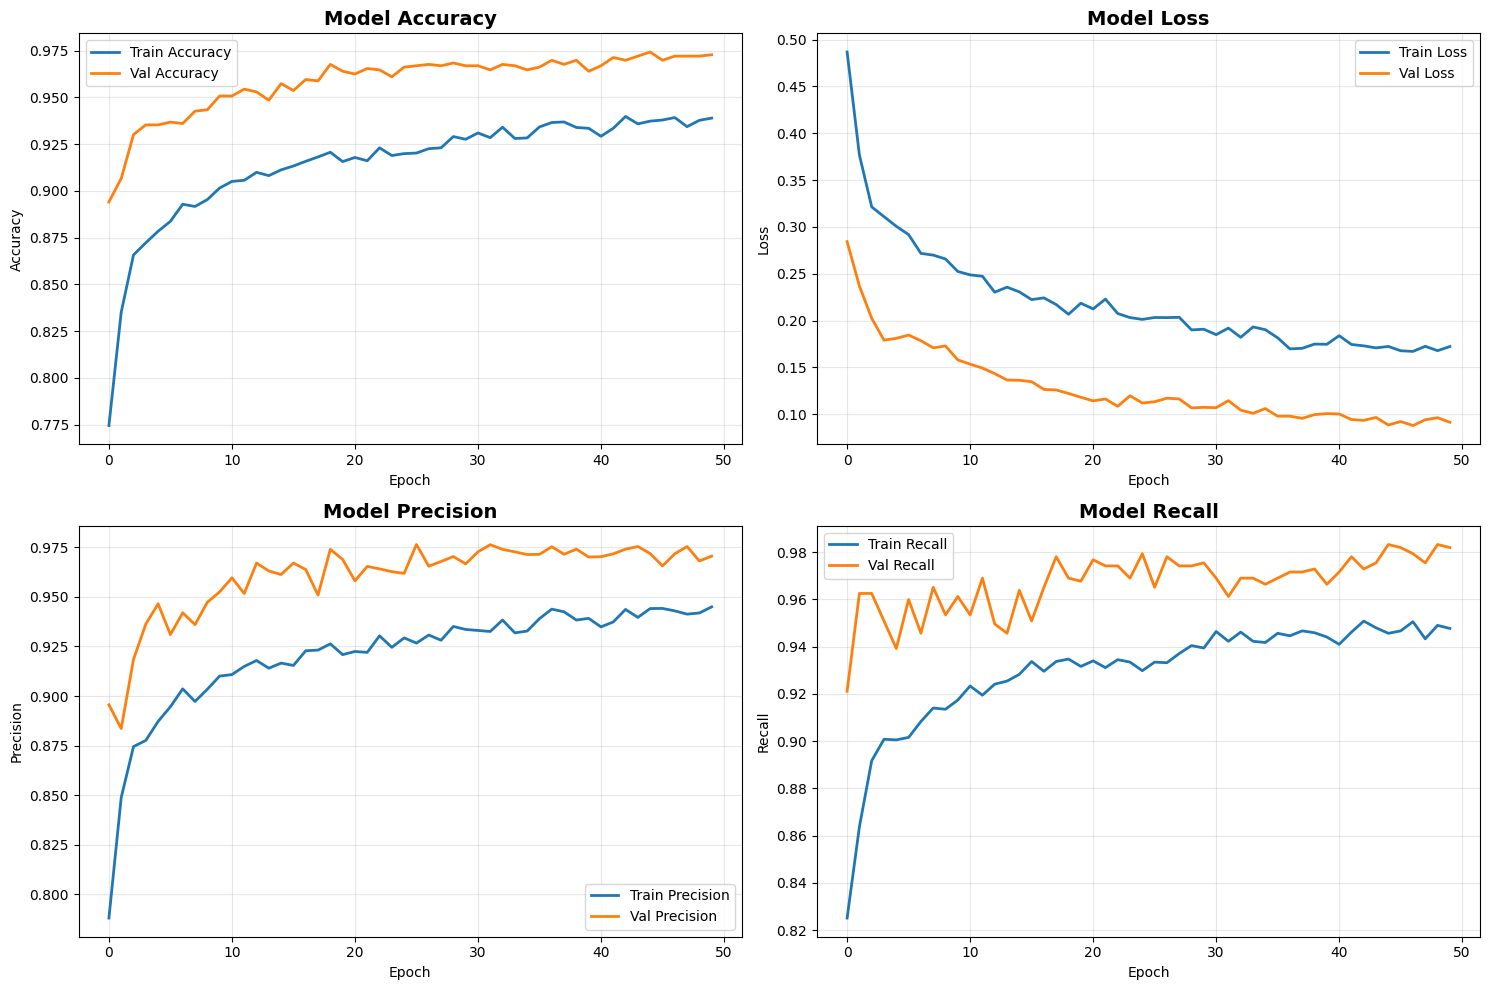

Available keys in history: ['accuracy', 'loss', 'precision_3', 'recall_3', 'val_accuracy', 'val_loss', 'val_precision_3', 'val_recall_3', 'learning_rate']


In [58]:
import matplotlib.pyplot as plt
import os

# -----------------------------------------------------------
# Helper logic to find the correct keys in the history object
# -----------------------------------------------------------
available_keys = history.history.keys()

# Find keys that contain 'precision' (e.g., 'precision', 'precision_1')
prec_key = next((k for k in available_keys if 'precision' in k and 'val' not in k), None)
val_prec_key = next((k for k in available_keys if 'precision' in k and 'val' in k), None)

# Find keys that contain 'recall' (e.g., 'recall', 'recall_1')
rec_key = next((k for k in available_keys if 'recall' in k and 'val' not in k), None)
val_rec_key = next((k for k in available_keys if 'recall' in k and 'val' in k), None)

# -----------------------------------------------------------
# Plotting Code
# -----------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. Accuracy (Standard keys)
if 'accuracy' in available_keys:
    axes[0, 0].plot(history.history['accuracy'], label='Train Accuracy', linewidth=2)
if 'val_accuracy' in available_keys:
    axes[0, 0].plot(history.history['val_accuracy'], label='Val Accuracy', linewidth=2)
axes[0, 0].set_title('Model Accuracy', fontsize=14, fontweight='bold')
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Accuracy')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# 2. Loss (Standard keys)
if 'loss' in available_keys:
    axes[0, 1].plot(history.history['loss'], label='Train Loss', linewidth=2)
if 'val_loss' in available_keys:
    axes[0, 1].plot(history.history['val_loss'], label='Val Loss', linewidth=2)
axes[0, 1].set_title('Model Loss', fontsize=14, fontweight='bold')
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('Loss')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# 3. Precision (Dynamic keys)
if prec_key:
    axes[1, 0].plot(history.history[prec_key], label='Train Precision', linewidth=2)
if val_prec_key:
    axes[1, 0].plot(history.history[val_prec_key], label='Val Precision', linewidth=2)
axes[1, 0].set_title('Model Precision', fontsize=14, fontweight='bold')
axes[1, 0].set_xlabel('Epoch')
axes[1, 0].set_ylabel('Precision')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)
if not prec_key:
    axes[1, 0].text(0.5, 0.5, 'Precision not tracked', ha='center', va='center')

# 4. Recall (Dynamic keys)
if rec_key:
    axes[1, 1].plot(history.history[rec_key], label='Train Recall', linewidth=2)
if val_rec_key:
    axes[1, 1].plot(history.history[val_rec_key], label='Val Recall', linewidth=2)
axes[1, 1].set_title('Model Recall', fontsize=14, fontweight='bold')
axes[1, 1].set_xlabel('Epoch')
axes[1, 1].set_ylabel('Recall')
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)
if not rec_key:
    axes[1, 1].text(0.5, 0.5, 'Recall not tracked', ha='center', va='center')

plt.tight_layout()

# Ensure directory exists before saving
if 'PROJECT_DIR' in locals():
    plt.savefig(os.path.join(PROJECT_DIR, "training_history.png"), dpi=150)
else:
    plt.savefig("training_history.png", dpi=150)

plt.show()

# Debug: Print available keys so you can see what they are actually named
print(f"Available keys in history: {list(history.history.keys())}")

In [59]:
print("\n" + "="*60)
print("FINAL EVALUATION")
print("="*60)

val_loss, val_accuracy, val_precision, val_recall = model.evaluate(val_generator)

print(f"\nValidation Loss: {val_loss:.4f}")
print(f"Validation Accuracy: {val_accuracy*100:.2f}%")
print(f"Validation Precision: {val_precision:.4f}")
print(f"Validation Recall: {val_recall:.4f}")
print(f"F1 Score: {2 * (val_precision * val_recall) / (val_precision + val_recall):.4f}")
print(f"\nModel saved to: {MODEL_SAVE_PATH}")



FINAL EVALUATION
43/43 ━━━━━━━━━━━━━━━━━━━━ 17s 353ms/step - accuracy: 0.5669 - loss: 0.6628 - precision_6: 0.5717 - recall_6: 0.9495

Validation Loss: 0.6628
Validation Accuracy: 56.69%
Validation Precision: 0.5717
Validation Recall: 0.9495
F1 Score: 0.7137

Model saved to: D:\CSE Code\CSE465 Project\model\banknote_classifier.h5


In [62]:
import json
import os

# Initialize an empty dictionary
history_dict = {}

# Dynamically loop through ALL keys present in history.history
# This prevents KeyErrors if 'precision' is named 'precision_1' or is missing entirely
for key in history.history.keys():
    # Convert numpy values to standard python floats (required for JSON)
    history_dict[key] = [float(x) for x in history.history[key]]

# Ensure PROJECT_DIR exists in standard scope (fallback if not defined)
if 'PROJECT_DIR' not in locals():
    PROJECT_DIR = "." 

# Define the file path
file_path = os.path.join(PROJECT_DIR, "training_history.json")

# Save to JSON
with open(file_path, 'w') as f:
    json.dump(history_dict, f, indent=4)

print(f"Training history saved to: {file_path}")
print(f"Successfully saved metrics: {list(history_dict.keys())}")

Training history saved to: D:\CSE Code\CSE465 Project\training_history.json
Successfully saved metrics: ['accuracy', 'loss', 'precision_3', 'recall_3', 'val_accuracy', 'val_loss', 'val_precision_3', 'val_recall_3', 'learning_rate']
